In [1]:
import pandas as pd
import numpy as np
import librosa
import os

In [2]:
df = pd.read_csv("../torgo_metadata.csv")

print(df.shape)

(17635, 9)


In [3]:
test_df = df.sample(10, random_state=42)

test_df[["filename", "condition", "speaker"]]

,filename,condition,speaker
15459,wav_arrayMic_M04S02_0289.wav,Dysarthria,M04
4688,wav_arrayMic_F01_0011.wav,Dysarthria,F01
4639,wav_headMic_FC03S03_0170.wav,Control,FC03
13441,wav_headMic_MC04S01_0249.wav,Control,MC04
9410,wav_arrayMic_MC03S01_0539.wav,Control,MC03
4385,wav_headMic_FC03S02_0305.wav,Control,FC03
9163,wav_arrayMic_MC03S01_0292.wav,Control,MC03
1087,wav_arrayMic_FC02S03_0568.wav,Control,FC02
13914,wav_arrayMic_M01S01_0068.wav,Dysarthria,M01
8731,wav_arrayMic_MC02S02_0173.wav,Control,MC02


In [4]:
def extract_waveform_features(file_path):

    audio, sr = librosa.load(file_path, sr=None)

    duration = len(audio) / sr

    rms = np.mean(librosa.feature.rms(y=audio))

    zcr = np.mean(
        librosa.feature.zero_crossing_rate(audio)
    )

    mean_amplitude = np.mean(np.abs(audio))

    max_amplitude = np.max(np.abs(audio))

    return {
        "duration": duration,
        "rms": rms,
        "zcr": zcr,
        "mean_amplitude": mean_amplitude,
        "max_amplitude": max_amplitude
    }

In [5]:
features = extract_waveform_features(
    df.iloc[0]["file"]
)

print(features)

{'duration': 9.3, 'rms': np.float32(0.022352729), 'zcr': np.float64(0.33372261597938147), 'mean_amplitude': np.float32(0.015804775), 'max_amplitude': np.float32(0.50613403)}


In [6]:
results = []

for index, row in test_df.iterrows():

    features = extract_waveform_features(row["file"])

    features["condition"] = row["condition"]
    features["gender"] = row["gender"]
    features["speaker"] = row["speaker"]
    features["microphone"] = row["microphone"]

    results.append(features)

test_features = pd.DataFrame(results)

print(test_features)

   duration       rms       zcr  mean_amplitude  max_amplitude   condition  \
0    5.1300  0.065946  0.254158        0.049658       0.569794  Dysarthria   
1    0.7500  0.043825  0.278727        0.035880       0.299713  Dysarthria   
2    2.2535  0.064859  0.094644        0.047715       1.000000     Control   
3    5.7200  0.228130  0.134875        0.168051       1.000000     Control   
4    2.1000  0.009777  0.532323        0.006437       0.354980     Control   
5    2.0950  0.045553  0.113148        0.030697       0.989075     Control   
6    1.3500  0.018213  0.530671        0.010879       0.519745     Control   
7    2.4000  0.006946  0.557900        0.004972       0.300812     Control   
8    3.9000  0.044766  0.511070        0.037084       0.561951  Dysarthria   
9    3.6000  0.015761  0.384109        0.010944       0.545624     Control   

   gender speaker microphone  
0    Male     M04   arrayMic  
1  Female     F01   arrayMic  
2  Female    FC03    headMic  
3    Male    MC04

In [10]:
def extract_waveform_features(file_path):

    try:
        audio, sr = librosa.load(file_path, sr=None)

        # Check if the audio file is empty
        if len(audio) == 0:
            return None

        duration = len(audio) / sr

        rms = np.mean(
            librosa.feature.rms(y=audio)
        )

        zcr = np.mean(
            librosa.feature.zero_crossing_rate(y=audio)
        )

        mean_amplitude = np.mean(
            np.abs(audio)
        )

        max_amplitude = np.max(
            np.abs(audio)
        )

        return {
            "duration": duration,
            "rms": rms,
            "zcr": zcr,
            "mean_amplitude": mean_amplitude,
            "max_amplitude": max_amplitude
        }

    except Exception as e:

        return None

In [11]:
test_df = df.head(10)

print(test_df[["filename", "condition", "speaker"]])

                        filename condition speaker
0  wav_arrayMic_FC01S01_0001.wav   Control    FC01
1  wav_arrayMic_FC01S01_0002.wav   Control    FC01
2  wav_arrayMic_FC01S01_0003.wav   Control    FC01
3  wav_arrayMic_FC01S01_0004.wav   Control    FC01
4  wav_arrayMic_FC01S01_0005.wav   Control    FC01
5  wav_arrayMic_FC01S01_0006.wav   Control    FC01
6  wav_arrayMic_FC01S01_0007.wav   Control    FC01
7  wav_arrayMic_FC01S01_0008.wav   Control    FC01
8  wav_arrayMic_FC01S01_0009.wav   Control    FC01
9  wav_arrayMic_FC01S01_0010.wav   Control    FC01


In [12]:
results = []

for index, row in test_df.iterrows():

    features = extract_waveform_features(row["file"])

    if features is not None:

        features["condition"] = row["condition"]
        features["gender"] = row["gender"]
        features["speaker"] = row["speaker"]
        features["microphone"] = row["microphone"]

        results.append(features)

test_features = pd.DataFrame(results)

print(test_features)

   duration       rms       zcr  mean_amplitude  max_amplitude condition  \
0      9.30  0.022353  0.333723        0.015805       0.506134   Control   
1      7.35  0.025352  0.306692        0.017020       0.506470   Control   
2      5.25  0.003137  0.573029        0.002655       0.050323   Control   
3      4.65  0.026444  0.135317        0.019084       0.252380   Control   
4      2.25  0.007828  0.558243        0.005541       0.248322   Control   
5      2.70  0.006265  0.586598        0.004520       0.165894   Control   
6      2.55  0.009237  0.463916        0.006914       0.514465   Control   
7      3.30  0.006847  0.598699        0.004561       0.470276   Control   
8      3.00  0.003511  0.622450        0.002570       0.101807   Control   
9      3.00  0.007313  0.554054        0.005584       0.179474   Control   

   gender speaker microphone  
0  Female    FC01   arrayMic  
1  Female    FC01   arrayMic  
2  Female    FC01   arrayMic  
3  Female    FC01   arrayMic  
4  Femal

In [13]:
for index, row in df.iterrows():

    try:
        audio, sr = librosa.load(row["file"], sr=None)

        if len(audio) == 0:
            print("EMPTY AUDIO:", index, row["file"])

    except Exception as e:
        print("ERROR:", index, row["file"])
        print(e)

EMPTY AUDIO: 255 ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayMic_FC01S01_0256.wav
ERROR: 6174 ../torgo\F_Dys\wav_headMic_F01\wav_headMic_F01_0067.wav
Error opening '../torgo\\F_Dys\\wav_headMic_F01\\wav_headMic_F01_0067.wav': Format not recognised.
ERROR: 6175 ../torgo\F_Dys\wav_headMic_F01\wav_headMic_F01_0068.wav
Error opening '../torgo\\F_Dys\\wav_headMic_F01\\wav_headMic_F01_0068.wav': Format not recognised.


In [14]:
results = []
problems = []

for index, row in df.iterrows():

    try:

        audio, sr = librosa.load(row["file"], sr=None)

        if len(audio) == 0:

            problems.append({
                "index": index,
                "file": row["file"],
                "reason": "Empty audio"
            })

            continue

        duration = len(audio) / sr

        rms = np.mean(
            librosa.feature.rms(y=audio)
        )

        zcr = np.mean(
            librosa.feature.zero_crossing_rate(y=audio)
        )

        mean_amplitude = np.mean(
            np.abs(audio)
        )

        max_amplitude = np.max(
            np.abs(audio)
        )

        results.append({

            "index": index,
            "duration": duration,
            "rms": rms,
            "zcr": zcr,
            "mean_amplitude": mean_amplitude,
            "max_amplitude": max_amplitude,

            "condition": row["condition"],
            "gender": row["gender"],
            "speaker": row["speaker"],
            "microphone": row["microphone"]

        })

    except Exception as e:

        problems.append({
            "index": index,
            "file": row["file"],
            "reason": str(e)
        })

In [16]:
waveform_features = pd.DataFrame(results)

problem_files = pd.DataFrame(problems)

In [17]:
print("Successful recordings:", len(waveform_features))

print("Problematic recordings:", len(problem_files))

print(problem_files)

Successful recordings: 17632
Problematic recordings: 3
   index                                               file  \
0    255  ../torgo\F_Con\wav_arrayMic_FC01S01\wav_arrayM...   
1   6174  ../torgo\F_Dys\wav_headMic_F01\wav_headMic_F01...   
2   6175  ../torgo\F_Dys\wav_headMic_F01\wav_headMic_F01...   

                                              reason  
0                                        Empty audio  
1  Error opening '../torgo\\F_Dys\\wav_headMic_F0...  
2  Error opening '../torgo\\F_Dys\\wav_headMic_F0...  


In [18]:
waveform_features.to_csv(
    "../torgo_waveform_features.csv",
    index=False
)

problem_files.to_csv(
    "../torgo_problem_files.csv",
    index=False
)

In [20]:
print(waveform_features.shape)
print(waveform_features.head())
print(waveform_features["condition"].value_counts())

(17632, 10)
   index  duration       rms       zcr  mean_amplitude  max_amplitude  \
0      0      9.30  0.022353  0.333723        0.015805       0.506134   
1      1      7.35  0.025352  0.306692        0.017020       0.506470   
2      2      5.25  0.003137  0.573029        0.002655       0.050323   
3      3      4.65  0.026444  0.135317        0.019084       0.252380   
4      4      2.25  0.007828  0.558243        0.005541       0.248322   

  condition  gender speaker microphone  
0   Control  Female    FC01   arrayMic  
1   Control  Female    FC01   arrayMic  
2   Control  Female    FC01   arrayMic  
3   Control  Female    FC01   arrayMic  
4   Control  Female    FC01   arrayMic  
condition
Control       11455
Dysarthria     6177
Name: count, dtype: int64


In [21]:
summary = waveform_features.groupby("condition")[
    ["duration", "rms", "zcr", "mean_amplitude", "max_amplitude"]
].mean()

print(summary)

            duration       rms       zcr  mean_amplitude  max_amplitude
condition                                                              
Control     2.820662  0.038137  0.293754        0.028218       0.509503
Dysarthria  3.615179  0.054255  0.236775        0.042937       0.560909


In [22]:
median_summary = waveform_features.groupby("condition")[
    ["duration", "rms", "zcr", "mean_amplitude", "max_amplitude"]
].median()

print(median_summary)

            duration       rms       zcr  mean_amplitude  max_amplitude
condition                                                              
Control        2.470  0.021780  0.276635        0.015504       0.438660
Dysarthria     2.685  0.037163  0.157400        0.028430       0.518738


In [23]:
std_summary = waveform_features.groupby("condition")[
    ["duration", "rms", "zcr", "mean_amplitude", "max_amplitude"]
].std()

print(std_summary)

            duration       rms       zcr  mean_amplitude  max_amplitude
condition                                                              
Control     1.445794  0.042624  0.205245        0.032632       0.319010
Dysarthria  4.507227  0.054404  0.180984        0.045612       0.279812


<Figure size 800x500 with 0 Axes>

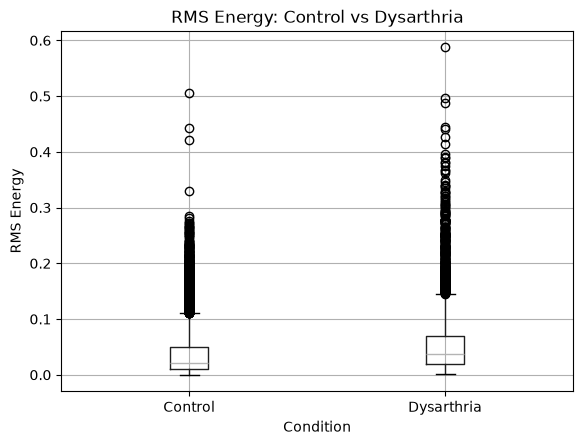

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

waveform_features.boxplot(
    column="rms",
    by="condition"
)

plt.title("RMS Energy: Control vs Dysarthria")
plt.suptitle("")
plt.xlabel("Condition")
plt.ylabel("RMS Energy")

plt.show()

<Figure size 800x500 with 0 Axes>

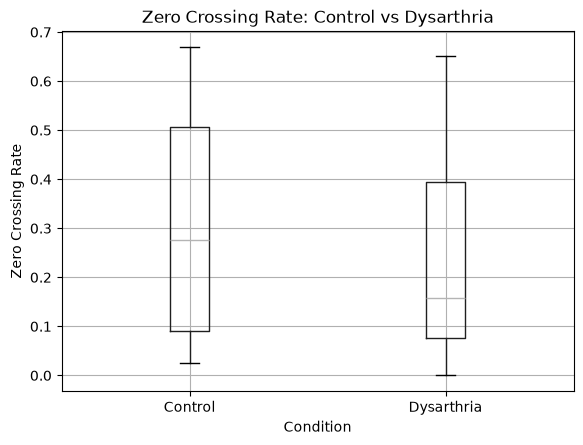

In [25]:
plt.figure(figsize=(8, 5))

waveform_features.boxplot(
    column="zcr",
    by="condition"
)

plt.title("Zero Crossing Rate: Control vs Dysarthria")
plt.suptitle("")
plt.xlabel("Condition")
plt.ylabel("Zero Crossing Rate")

plt.show()

<Figure size 800x500 with 0 Axes>

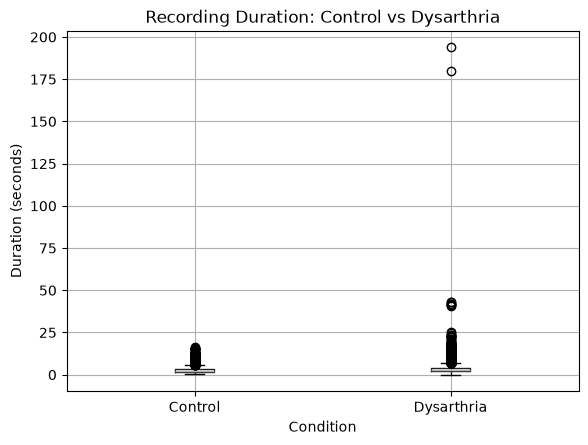

In [26]:
plt.figure(figsize=(8, 5))

waveform_features.boxplot(
    column="duration",
    by="condition"
)

plt.title("Recording Duration: Control vs Dysarthria")
plt.suptitle("")
plt.xlabel("Condition")
plt.ylabel("Duration (seconds)")

plt.show()

In [27]:
gender_summary = waveform_features.groupby(
    ["gender", "condition"]
)[
    ["duration", "rms", "zcr", "mean_amplitude", "max_amplitude"]
].mean()

print(gender_summary)

                   duration       rms       zcr  mean_amplitude  max_amplitude
gender condition                                                              
Female Control     2.934401  0.037494  0.308511        0.027124       0.562559
       Dysarthria  2.931940  0.033672  0.300398        0.025463       0.423078
Male   Control     2.742179  0.038580  0.283572        0.028973       0.472893
       Dysarthria  4.046082  0.067235  0.196649        0.053957       0.647836


In [33]:
microphone_summary = waveform_features.groupby(
    ["microphone", "condition"]
)[
    ["duration", "rms", "zcr", "mean_amplitude", "max_amplitude"]
].mean()

print(microphone_summary)

                       duration       rms       zcr  mean_amplitude  \
microphone condition                                                  
arrayMic   Control     2.900367  0.013940  0.464587        0.009870   
           Dysarthria  3.455503  0.046314  0.385269        0.036461   
headMic    Control     2.725458  0.067039  0.089704        0.050133   
           Dysarthria  3.784715  0.062685  0.079112        0.049812   

                       max_amplitude  
microphone condition                  
arrayMic   Control          0.305339  
           Dysarthria       0.459236  
headMic    Control          0.753365  
           Dysarthria       0.668860  


In [34]:
speaker_summary = waveform_features.groupby(
    ["speaker", "condition"]
)[
    ["duration", "rms", "zcr", "mean_amplitude", "max_amplitude"]
].mean()

print(speaker_summary)

                    duration       rms       zcr  mean_amplitude  \
speaker condition                                                  
F01     Dysarthria  2.798828  0.035122  0.219220        0.027335   
F03     Dysarthria  2.727645  0.022703  0.299782        0.016960   
F04     Dysarthria  3.399746  0.055513  0.332592        0.042108   
FC01    Control     3.768513  0.022018  0.351336        0.016883   
FC02    Control     2.965099  0.035756  0.322268        0.025341   
FC03    Control     2.724637  0.042709  0.283951        0.031291   
M01     Dysarthria  4.043702  0.075139  0.222735        0.061196   
M02     Dysarthria  3.777831  0.068737  0.206047        0.054666   
M03     Dysarthria  3.528237  0.041661  0.289395        0.030762   
M04     Dysarthria  4.491245  0.066034  0.162200        0.051455   
M05     Dysarthria  4.556397  0.090206  0.072840        0.077074   
MC01    Control     3.130382  0.021658  0.285707        0.016068   
MC02    Control     3.675715  0.035987  0.350551

In [37]:
print(speaker_summary.to_string())

                    duration       rms       zcr  mean_amplitude  max_amplitude
speaker condition                                                              
F01     Dysarthria  2.798828  0.035122  0.219220        0.027335       0.357805
F03     Dysarthria  2.727645  0.022703  0.299782        0.016960       0.328530
F04     Dysarthria  3.399746  0.055513  0.332592        0.042108       0.640976
FC01    Control     3.768513  0.022018  0.351336        0.016883       0.324636
FC02    Control     2.965099  0.035756  0.322268        0.025341       0.596157
FC03    Control     2.724637  0.042709  0.283951        0.031291       0.574440
M01     Dysarthria  4.043702  0.075139  0.222735        0.061196       0.580721
M02     Dysarthria  3.777831  0.068737  0.206047        0.054666       0.578048
M03     Dysarthria  3.528237  0.041661  0.289395        0.030762       0.701582
M04     Dysarthria  4.491245  0.066034  0.162200        0.051455       0.707445
M05     Dysarthria  4.556397  0.090206  

In [38]:
speaker_summary.reset_index().head()

,speaker,condition,duration,rms,zcr,mean_amplitude,max_amplitude
0,F01,Dysarthria,2.798828,0.035122,0.219220,0.027335,0.357805
1,F03,Dysarthria,2.727645,0.022703,0.299782,0.016960,0.328530
2,F04,Dysarthria,3.399746,0.055513,0.332592,0.042108,0.640976
3,FC01,Control,3.768513,0.022018,0.351336,0.016883,0.324636
4,FC02,Control,2.965099,0.035756,0.322268,0.025341,0.596157


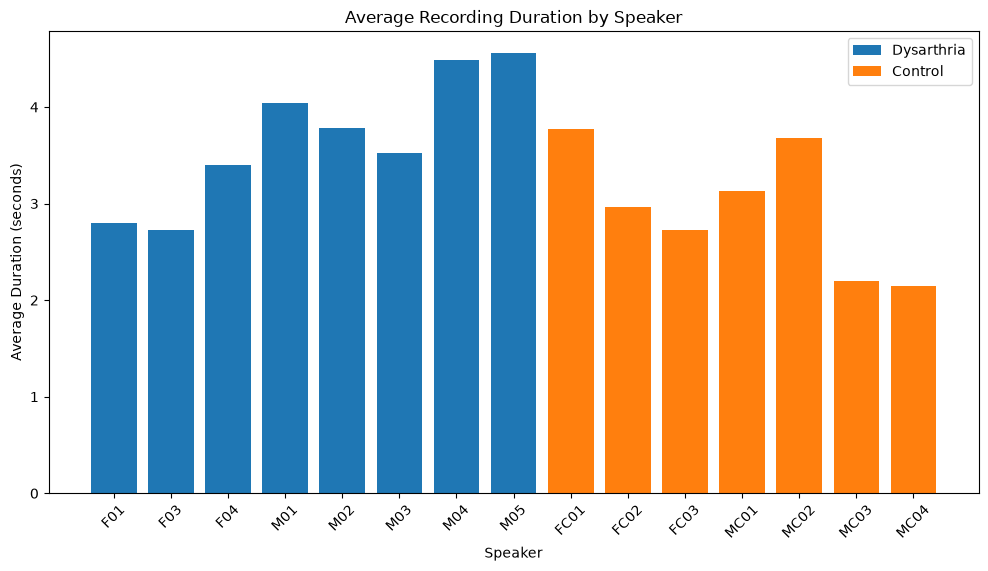

In [39]:
import matplotlib.pyplot as plt

speaker_plot = speaker_summary.reset_index()

plt.figure(figsize=(12, 6))

for condition in speaker_plot["condition"].unique():

    data = speaker_plot[
        speaker_plot["condition"] == condition
    ]

    plt.bar(
        data["speaker"],
        data["duration"],
        label=condition
    )

plt.title("Average Recording Duration by Speaker")
plt.xlabel("Speaker")
plt.ylabel("Average Duration (seconds)")
plt.legend()

plt.xticks(rotation=45)

plt.show()

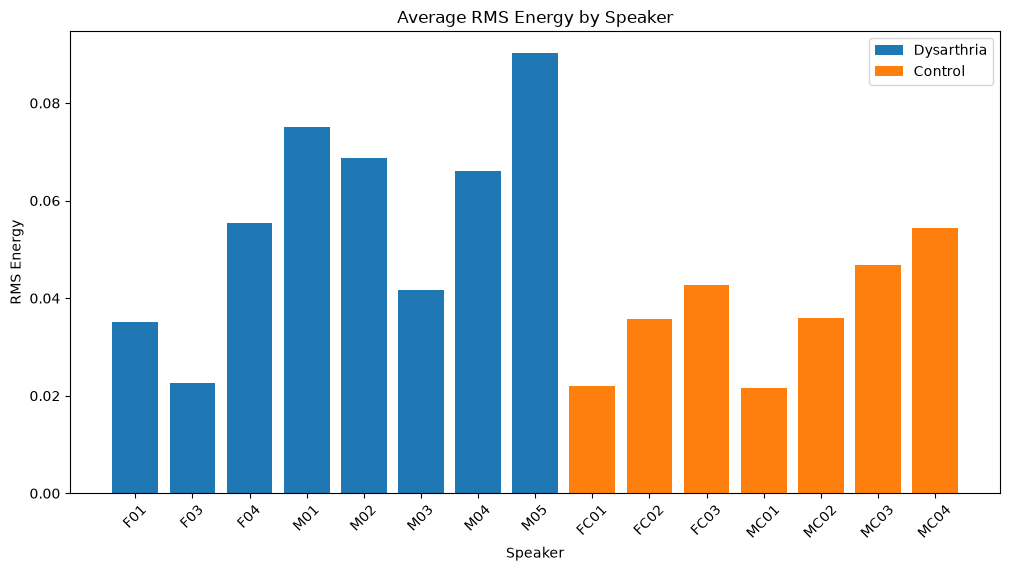

In [40]:
plt.figure(figsize=(12, 6))

for condition in speaker_plot["condition"].unique():

    data = speaker_plot[
        speaker_plot["condition"] == condition
    ]

    plt.bar(
        data["speaker"],
        data["rms"],
        label=condition
    )

plt.title("Average RMS Energy by Speaker")
plt.xlabel("Speaker")
plt.ylabel("RMS Energy")
plt.legend()

plt.xticks(rotation=45)

plt.show()

In [43]:
print(
    "Recordings longer than 20 seconds:",
    (waveform_features["duration"] > 20).sum()
)

Recordings longer than 20 seconds: 22


In [44]:
long_recordings = waveform_features[
    waveform_features["duration"] > 20
]

print(long_recordings[
    ["index", "duration", "condition", "gender", "speaker", "microphone"]
].sort_values("duration", ascending=False).to_string(index=False))


print("Longest recording:")
print(long_recordings["duration"].max())

print("\nShortest of the >20 sec recordings:")
print(long_recordings["duration"].min())


print(
    long_recordings["condition"].value_counts()
)

print(
    long_recordings["gender"].value_counts()
)

print(
    long_recordings["speaker"].value_counts()
)

 index   duration  condition gender speaker microphone
  6359 193.828625 Dysarthria Female     F03    headMic
 15876 179.943125 Dysarthria   Male     M01    headMic
 16419  43.155062 Dysarthria   Male     M03    headMic
 14704  42.842813 Dysarthria   Male     M03   arrayMic
 16465  41.810063 Dysarthria   Male     M03    headMic
 14814  41.621563 Dysarthria   Male     M03   arrayMic
 14958  41.187750 Dysarthria   Male     M03   arrayMic
 16575  41.085062 Dysarthria   Male     M03    headMic
 16723  40.490063 Dysarthria   Male     M03    headMic
 17139  25.315000 Dysarthria   Male     M05    headMic
 15092  24.750000 Dysarthria   Male     M04   arrayMic
 16922  23.590062 Dysarthria   Male     M04    headMic
 15141  23.250000 Dysarthria   Male     M04   arrayMic
 17095  23.175000 Dysarthria   Male     M04    headMic
 15497  22.941312 Dysarthria   Male     M05   arrayMic
 15283  22.870000 Dysarthria   Male     M04   arrayMic
  5747  22.650000 Dysarthria Female     F04   arrayMic
 15452  22

In [48]:
long_recordings = waveform_features[
    waveform_features["duration"] > 20
].sort_values("duration", ascending=False)

In [49]:
print(
    df.loc[
        long_recordings["index"],
        ["file", "condition", "gender", "speaker", "microphone"]
    ].to_string(index=False))

                                                           file  condition gender speaker microphone
  ../torgo\F_Dys\wav_headMic_F03S01\wav_headMic_F03S01_0118.wav Dysarthria Female     F03    headMic
  ../torgo\M_Dys\wav_headMic_M01S02\wav_headMic_M01S02_0180.wav Dysarthria   Male     M01    headMic
  ../torgo\M_Dys\wav_headMic_M03S02\wav_headMic_M03S02_0027.wav Dysarthria   Male     M03    headMic
../torgo\M_Dys\wav_arrayMic_M03S02\wav_arrayMic_M03S02_0073.wav Dysarthria   Male     M03   arrayMic
  ../torgo\M_Dys\wav_headMic_M03S02\wav_headMic_M03S02_0073.wav Dysarthria   Male     M03    headMic
../torgo\M_Dys\wav_arrayMic_M03S02\wav_arrayMic_M03S02_0183.wav Dysarthria   Male     M03   arrayMic
../torgo\M_Dys\wav_arrayMic_M03S02\wav_arrayMic_M03S02_0331.wav Dysarthria   Male     M03   arrayMic
  ../torgo\M_Dys\wav_headMic_M03S02\wav_headMic_M03S02_0183.wav Dysarthria   Male     M03    headMic
  ../torgo\M_Dys\wav_headMic_M03S02\wav_headMic_M03S02_0331.wav Dysarthria   Male     M03  

In [51]:
long_recordings = waveform_features[
    waveform_features["duration"] > 20
].sort_values("duration", ascending=False)

In [52]:
for idx in long_recordings.index:
    print(df.loc[idx, "file"])

../torgo\F_Dys\wav_headMic_F03S01\wav_headMic_F03S01_0115.wav
../torgo\M_Dys\wav_headMic_M01S02\wav_headMic_M01S02_0177.wav
../torgo\M_Dys\wav_headMic_M03S02\wav_headMic_M03S02_0024.wav
../torgo\M_Dys\wav_arrayMic_M03S02\wav_arrayMic_M03S02_0070.wav
../torgo\M_Dys\wav_headMic_M03S02\wav_headMic_M03S02_0070.wav
../torgo\M_Dys\wav_arrayMic_M03S02\wav_arrayMic_M03S02_0180.wav
../torgo\M_Dys\wav_arrayMic_M03S02\wav_arrayMic_M03S02_0328.wav
../torgo\M_Dys\wav_headMic_M03S02\wav_headMic_M03S02_0180.wav
../torgo\M_Dys\wav_headMic_M03S02\wav_headMic_M03S02_0328.wav
../torgo\M_Dys\wav_headMic_M05S01\wav_headMic_M05S01_0025.wav
../torgo\M_Dys\wav_arrayMic_M04S01\wav_arrayMic_M04S01_0041.wav
../torgo\M_Dys\wav_headMic_M04S02\wav_headMic_M04S02_0106.wav
../torgo\M_Dys\wav_arrayMic_M04S01\wav_arrayMic_M04S01_0091.wav
../torgo\M_Dys\wav_headMic_M04S02\wav_headMic_M04S02_0279.wav
../torgo\M_Dys\wav_arrayMic_M05S01\wav_arrayMic_M05S01_0025.wav
../torgo\M_Dys\wav_arrayMic_M04S02\wav_arrayMic_M04S02_010

In [53]:

long_file = df.loc[6359, "file"]

print(long_file)


long_audio, long_sr = librosa.load(
    long_file,
    sr=None
)


../torgo\F_Dys\wav_headMic_F03S01\wav_headMic_F03S01_0118.wav


In [47]:
print("Sampling rate:", long_sr)
print("Number of samples:", len(long_audio))
print("Duration:", len(long_audio) / long_sr)


Sampling rate: 16000
Number of samples: 3101258
Duration: 193.828625


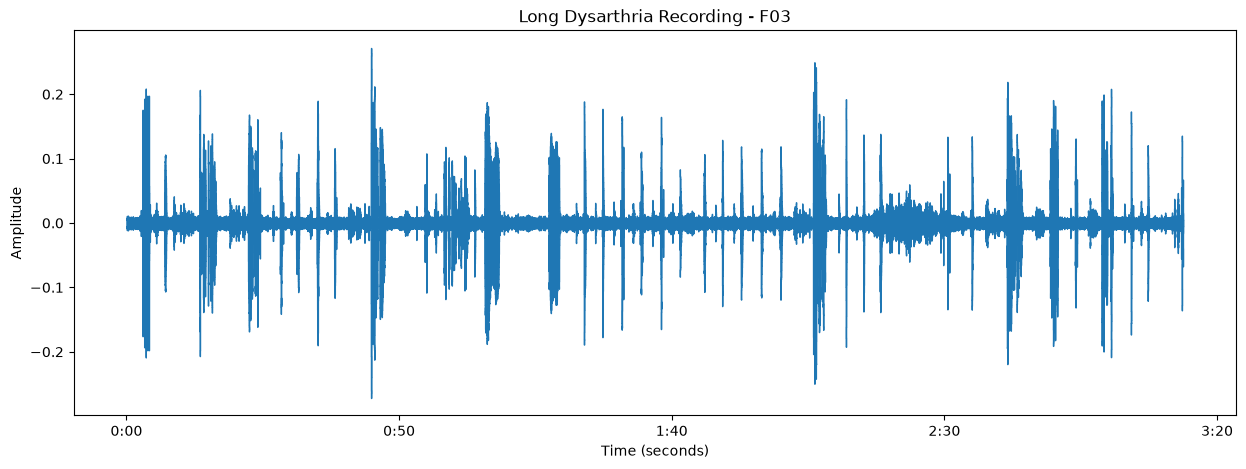

In [46]:
plt.figure(figsize=(15, 5))

librosa.display.waveshow(
    long_audio,
    sr=long_sr
)

plt.title("Long Dysarthria Recording - F03")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

In [54]:
intervals = librosa.effects.split(
    long_audio,
    top_db=30
)

speech_duration = 0

for start, end in intervals:
    speech_duration += (end - start) / long_sr

total_duration = len(long_audio) / long_sr

silence_duration = total_duration - speech_duration

print("Total duration:", round(total_duration, 2), "seconds")
print("Speech/activity duration:", round(speech_duration, 2), "seconds")
print("Silence/low-energy duration:", round(silence_duration, 2), "seconds")

print(
    "Speech percentage:",
    round((speech_duration / total_duration) * 100, 2), "%"
)

print(
    "Silence percentage:",
    round((silence_duration / total_duration) * 100, 2), "%"
)


Total duration: 193.83 seconds
Speech/activity duration: 126.66 seconds
Silence/low-energy duration: 67.17 seconds
Speech percentage: 65.34 %
Silence percentage: 34.66 %
